# Chapter 5 — Classification

**Mata Kuliah:** Deep Learning
**Buku:** Practical Statistics for Data Scientists
**Chapter:** 5 — Classification

## Tujuan

Pada chapter ini dilakukan reproduksi kode Python dan pembahasan
konsep **classification**, yaitu bentuk supervised learning untuk
memprediksi kategori dari suatu record (misalnya *paid off* atau
*default*).

Pembahasan meliputi:
1. Naive Bayes
2. Discriminant Analysis
3. Logistic Regression
4. Evaluating Classification Models
5. Strategies for Imbalanced Data

Notebook ini dijalankan di **Google Colab**. Seluruh dataset dibaca
langsung dari repository resmi buku, sehingga tidak perlu mengunggah
file apa pun.

## Pendahuluan Classification

Data scientist sering diminta mengotomatiskan keputusan bisnis,
misalnya:

- Apakah sebuah email adalah phishing?
- Apakah pelanggan akan berhenti berlangganan (churn)?
- Apakah pengguna web akan mengklik iklan?

Semua contoh tersebut adalah **classification problem**, yaitu
supervised learning di mana model dilatih pada data yang hasilnya
sudah diketahui, lalu dipakai untuk data yang hasilnya belum diketahui.

Tujuan utamanya biasanya memprediksi apakah suatu record bernilai
**1** atau **0** (misalnya default / paid off). Dalam beberapa kasus
ada lebih dari dua kategori.

### Probabilitas (propensity) dan cutoff

Sering kali yang dibutuhkan bukan hanya label biner, tetapi
**probabilitas** bahwa suatu record termasuk ke kelas yang diminati
(disebut *propensity score*). Di scikit-learn, sebagian besar model
klasifikasi menyediakan dua metode:

- `predict` — mengembalikan kelas hasil prediksi
- `predict_proba` — mengembalikan probabilitas untuk setiap kelas

Pendekatan umum dengan **cutoff probability**:

1. Tentukan cutoff probability untuk kelas yang diminati.
2. Estimasi probabilitas record tersebut menggunakan model apa saja.
3. Jika probabilitasnya di atas cutoff, record dimasukkan ke kelas
   yang diminati.

Semakin tinggi cutoff, semakin sedikit record yang diprediksi sebagai
1. Semakin rendah cutoff, semakin banyak record yang diprediksi
sebagai 1.

### Lebih dari dua kategori?

Sebagian besar masalah bersifat biner. Jika ada lebih dari dua hasil,
masalahnya sering dapat diubah menjadi beberapa masalah biner
berurutan. Contoh: untuk memprediksi kontrak pelanggan, pertama
prediksi apakah pelanggan churn atau tidak, lalu jika tidak churn,
prediksi jenis kontraknya.

## Import Library

In [1]:
# Library tambahan yang belum tersedia secara default di Google Colab
!pip install -q pygam imbalanced-learn

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.naive_bayes import MultinomialNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (confusion_matrix, precision_recall_fscore_support,
                             roc_curve, roc_auc_score, accuracy_score)

import statsmodels.api as sm
import statsmodels.formula.api as smf

# Alamat folder data pada repository resmi buku
DATA_URL = ('https://raw.githubusercontent.com/gedeck/'
            'practical-statistics-for-data-scientists/master/data/')

%matplotlib inline
sns.set_theme(style="whitegrid")

## Membaca Dataset

Dataset yang digunakan adalah data pinjaman pribadi dari
**LendingClub** (peer-to-peer lending). Tujuannya memprediksi apakah
sebuah pinjaman akan **paid off** (lunas) atau **default** (gagal
bayar).

- `loan_data` — data pinjaman utama (seimbang: setengah *default*,
  setengah *paid off*)
- `loan3000` — sampel 3.000 pinjaman dengan variabel yang dipilih

In [3]:
loan_data = pd.read_csv(DATA_URL + 'loan_data.csv.gz')

# Ubah kolom hasil dan kolom kategorikal menjadi tipe category
loan_data['outcome'] = loan_data['outcome'].astype('category')
for col in ['purpose_', 'home_', 'emp_len_']:
    loan_data[col] = loan_data[col].astype('category')

print(loan_data.shape)
loan_data.head()

(45342, 21)


,Unnamed: 0,status,loan_amnt,term,annual_inc,dti,payment_inc_ratio,revol_bal,revol_util,purpose,...,delinq_2yrs_zero,pub_rec_zero,open_acc,grade,outcome,emp_length,purpose_,home_,emp_len_,borrower_score
0,1,Charged Off,2500,60 months,30000,1.00,2.39320,1687,9.4,car,...,1,1,3,4.8,default,1,major_purchase,RENT,> 1 Year,0.65
1,2,Charged Off,5600,60 months,40000,5.55,4.57170,5210,32.6,small_business,...,1,1,11,1.4,default,5,small_business,OWN,> 1 Year,0.80
2,3,Charged Off,5375,60 months,15000,18.08,9.71600,9279,36.5,other,...,1,1,2,6.0,default,1,other,RENT,> 1 Year,0.60
3,4,Charged Off,9000,36 months,30000,10.08,12.21520,10452,91.7,debt_consolidation,...,1,1,4,4.2,default,1,debt_consolidation,RENT,> 1 Year,0.50
4,5,Charged Off,10000,36 months,100000,7.06,3.90888,11997,55.5,other,...,1,1,14,5.4,default,4,other,RENT,> 1 Year,0.55


In [4]:
loan3000 = pd.read_csv(DATA_URL + 'loan3000.csv')
loan3000['outcome'] = loan3000['outcome'].astype('category')

print(loan3000.shape)
loan3000.head()

(3000, 6)


,Unnamed: 0,outcome,purpose_,dti,borrower_score,payment_inc_ratio
0,32109,paid off,debt_consolidation,21.23,0.40,5.11135
1,16982,default,credit_card,15.49,0.40,5.43165
2,25335,paid off,debt_consolidation,27.30,0.70,9.23003
3,34580,paid off,major_purchase,21.11,0.40,2.33482
4,14424,default,debt_consolidation,16.46,0.45,12.10320


In [5]:
print(loan_data['outcome'].value_counts())
print()
print('Kategori outcome:', list(loan_data['outcome'].cat.categories))

outcome
default     22671
paid off    22671
Name: count, dtype: int64

Kategori outcome: ['default', 'paid off']


**Catatan urutan kelas:** scikit-learn mengurutkan label kelas secara
alfabet pada atribut `classes_`, sehingga urutannya adalah
`['default', 'paid off']`. Kolom pertama pada `predict_proba` adalah
probabilitas **default**, dan kolom kedua adalah probabilitas
**paid off**. Pada notebook ini nama kolom selalu diambil dari
`model.classes_` agar tidak tertukar.

# 1. Naive Bayes

Algoritma **naive Bayes** menggunakan probabilitas munculnya nilai
predictor *jika hasilnya diketahui*, untuk memperkirakan hal yang
sebenarnya ingin diketahui: probabilitas hasil Y = i *jika nilai
predictor diketahui*.

### Key Terms

- **Conditional probability** — probabilitas suatu kejadian jika
  kejadian lain sudah terjadi, ditulis P(X<sub>j</sub> | Y = i).
- **Posterior probability** — probabilitas suatu hasil setelah
  informasi predictor diperhitungkan (berbeda dengan *prior
  probability* yang belum memakai informasi predictor).

### Exact Bayesian Classification

Bayesian classification yang "eksak" bekerja seperti ini untuk setiap
record yang akan diklasifikasikan:

1. Cari semua record lain dengan profil predictor yang **sama persis**.
2. Tentukan kelas yang paling banyak muncul di antara record tersebut.
3. Berikan kelas itu pada record baru.

Pada naive Bayes standar, predictor harus berupa **variabel
kategorikal**.

### Kenapa exact Bayesian classification tidak praktis?

Jika jumlah predictor lebih dari beberapa saja, sebagian besar record
tidak akan punya pasangan yang persis sama. Menambah satu variabel
baru dengan 5 kategori yang sama sering muncul akan menurunkan peluang
menemukan pasangan yang cocok sebanyak 5 kali lipat.

### The Naive Solution

Pada solusi naive Bayes, perhitungan probabilitas tidak lagi dibatasi
pada record yang cocok persis, tetapi memakai **seluruh data**:

1. Untuk respons biner Y = i, hitung probabilitas bersyarat setiap
   predictor, P(X<sub>j</sub> | Y = i), yaitu proporsi nilai
   X<sub>j</sub> di antara record dengan Y = i pada training set.
2. Kalikan probabilitas-probabilitas tersebut, lalu kalikan dengan
   proporsi record yang termasuk Y = i.
3. Ulangi langkah 1 dan 2 untuk semua kelas.
4. Probabilitas hasil i adalah nilai kelas i dari langkah 2 dibagi
   jumlah nilai semua kelas.
5. Berikan record ke kelas dengan probabilitas tertinggi.

Rumusnya (dengan asumsi independensi bersyarat):

$$
P(Y=i \mid X_1,\dots,X_p) =
\frac{P(Y=i)\,P(X_1\mid Y=i)\cdots P(X_p\mid Y=i)}
{\sum_{k} P(Y=k)\,P(X_1\mid Y=k)\cdots P(X_p\mid Y=k)}
$$

Disebut **naive** karena kita menyederhanakan bahwa probabilitas
bersyarat dari seluruh vektor predictor cukup didekati dengan hasil
kali probabilitas masing-masing predictor. Artinya, X<sub>j</sub>
dianggap independen terhadap predictor lain.

### Contoh: Naive Bayes pada Data Pinjaman

Predictor yang digunakan adalah `purpose_`, `home_`, dan `emp_len_`.
Variabel kategorikal diubah menjadi dummy variable terlebih dahulu,
kemudian model `MultinomialNB` dilatih.

Parameter `alpha` adalah **Laplace smoothing**. Smoothing mencegah
probabilitas nol ketika suatu kategori tidak muncul pada training data.

In [6]:
predictors = ['purpose_', 'home_', 'emp_len_']
outcome = 'outcome'

X = pd.get_dummies(loan_data[predictors], prefix='', prefix_sep='', dtype=float)
y = loan_data[outcome]

naive_model = MultinomialNB(alpha=0.01, fit_prior=True)
naive_model.fit(X, y)

print('Kelas:', list(naive_model.classes_))

Kelas: [np.str_('default'), np.str_('paid off')]


Probabilitas bersyarat P(X<sub>j</sub> | Y = i) dapat diturunkan dari
atribut `feature_log_prob_`.

In [7]:
conditional_probs = pd.DataFrame(
    np.exp(naive_model.feature_log_prob_),
    index=naive_model.classes_,
    columns=X.columns
)
conditional_probs.round(4)

,credit_card,debt_consolidation,home_improvement,major_purchase,medical,other,small_business,MORTGAGE,OWN,RENT,< 1 Year,> 1 Year
default,0.0505,0.1919,0.0199,0.0124,0.0048,0.0385,0.0152,0.1438,0.0278,0.1618,0.0158,0.3176
paid off,0.0625,0.1841,0.0238,0.0179,0.0047,0.0333,0.0070,0.1632,0.0270,0.1432,0.0104,0.3230


### Memprediksi Pinjaman Baru

Model dipakai untuk memprediksi hasil pinjaman. Sebagai contoh,
digunakan record ke-146 (indeks 146) dari dataset.

In [8]:
new_loan = X.loc[146:146, :]

print('predicted class: ', naive_model.predict(new_loan)[0])

probabilities = pd.DataFrame(naive_model.predict_proba(new_loan),
                             columns=naive_model.classes_)
print('predicted probabilities')
print(probabilities)

predicted class:  default
predicted probabilities
    default  paid off
0  0.653696  0.346304


Hasil ini menunjukkan kelas prediksi beserta **posterior probability**
untuk masing-masing kelas.

Naive Bayes dikenal menghasilkan estimasi probabilitas yang **bias**.
Namun jika tujuannya hanya **mengurutkan** record berdasarkan
probabilitas Y = 1, estimasi yang tidak bias tidak diperlukan, dan
naive Bayes tetap memberikan hasil yang baik.

### Numeric Predictor Variables

Naive Bayes standar hanya bekerja pada predictor kategorikal. Untuk
predictor numerik ada dua pendekatan:

1. **Binning** — ubah predictor numerik menjadi kategori, lalu
   gunakan algoritma seperti di atas.
2. **Model probabilitas** — gunakan distribusi probabilitas (misalnya
   distribusi normal) untuk mengestimasi P(X<sub>j</sub> | Y = i).

> Jika suatu kategori predictor tidak ada pada training data, algoritma
> akan memberi probabilitas nol pada hasil di data baru. Sebagian besar
> implementasi menggunakan smoothing (Laplace smoothing) untuk
> mencegah hal ini.

### Key Ideas — Naive Bayes

- Naive Bayes bekerja dengan predictor dan outcome kategorikal.
- Naive Bayes menjawab pertanyaan: *di dalam setiap kategori outcome,
  kategori predictor mana yang paling mungkin muncul?*
- Informasi tersebut kemudian dibalik untuk mengestimasi probabilitas
  kategori outcome, jika nilai predictor diketahui.

# 2. Discriminant Analysis

**Discriminant analysis** adalah statistical classifier paling awal,
diperkenalkan oleh R. A. Fisher pada tahun 1936. Bentuk yang paling
sering digunakan adalah **linear discriminant analysis (LDA)**.

LDA kini lebih jarang dipakai karena munculnya metode yang lebih
canggih (tree model, logistic regression). Namun LDA masih dapat
ditemui dan berhubungan dengan metode lain yang lebih luas
digunakan, misalnya principal components analysis (PCA).

> Linear Discriminant Analysis **tidak sama** dengan Latent Dirichlet
> Allocation (yang juga disingkat LDA dan dipakai pada pemrosesan
> bahasa alami).

### Key Terms

- **Covariance** — ukuran seberapa besar satu variabel bergerak
  bersama variabel lain (besaran dan arah yang mirip).
- **Discriminant function** — fungsi yang jika diterapkan pada
  predictor akan memaksimalkan pemisahan antar kelas.
- **Discriminant weights** — skor hasil penerapan discriminant
  function, yang dipakai untuk mengestimasi probabilitas masuk ke
  salah satu kelas.

### Covariance Matrix

Covariance antara dua variabel x dan z:

$$
s_{x,z} = \frac{\sum_{i=1}^{n}(x_i-\bar{x})(z_i-\bar{z})}{n-1}
$$

Seperti korelasi, nilai positif menunjukkan hubungan positif dan nilai
negatif menunjukkan hubungan negatif. Bedanya, korelasi dibatasi
antara -1 dan 1, sedangkan skala covariance bergantung pada skala
variabel.

**Covariance matrix** berisi varians masing-masing variabel pada
diagonal, dan covariance antar pasangan variabel pada elemen di luar
diagonal.

### Fisher's Linear Discriminant

Untuk masalah klasifikasi biner dengan dua variabel numerik (x, z),
Fisher's linear discriminant membedakan variasi **antar kelompok**
dari variasi **di dalam kelompok**. LDA memaksimalkan rasio:

$$
\frac{SS_{between}}{SS_{within}}
$$

- $SS_{between}$ — kuadrat jarak antara rata-rata kedua kelompok.
- $SS_{within}$ — sebaran di sekitar rata-rata dalam tiap kelompok,
  yang diboboti oleh covariance matrix.

Dengan memaksimalkan variasi antar kelompok dan meminimalkan variasi
di dalam kelompok, metode ini menghasilkan pemisahan terbesar antara
dua kelompok.

### Contoh: LDA pada Data Pinjaman

Digunakan dua predictor: `borrower_score` dan `payment_inc_ratio`.

In [9]:
predictors = ['borrower_score', 'payment_inc_ratio']
outcome = 'outcome'

X = loan3000[predictors]
y = loan3000[outcome]

loan_lda = LinearDiscriminantAnalysis()
loan_lda.fit(X, y)

# Bobot discriminant (scalings) hasil estimasi
pd.DataFrame(loan_lda.scalings_, index=X.columns, columns=['LD1'])

,LD1
borrower_score,7.175839
payment_inc_ratio,-0.099676


> **Using Discriminant Analysis for Feature Selection**
> Jika predictor dinormalisasi sebelum LDA, bobot discriminant dapat
> dipakai sebagai ukuran *variable importance*, sehingga menjadi
> metode feature selection yang efisien secara komputasi.

Metode `predict_proba` mengembalikan probabilitas *default* dan
*paid off*.

In [10]:
pred = pd.DataFrame(loan_lda.predict_proba(loan3000[predictors]),
                    columns=loan_lda.classes_)
pred.head()

,default,paid off
0,0.553544,0.446456
1,0.558953,0.441047
2,0.272696,0.727304
3,0.506254,0.493746
4,0.609952,0.390048


### Visualisasi Decision Boundary LDA

Garis batas keputusan dihitung dari `scalings_` dan titik tengah
(center) kedua rata-rata kelas. Titik di sebelah kiri garis diagonal
diprediksi *default* (probabilitas > 0,5). Titik yang semakin jauh dari
garis memiliki tingkat keyakinan lebih tinggi (probabilitas semakin
jauh dari 0,5).

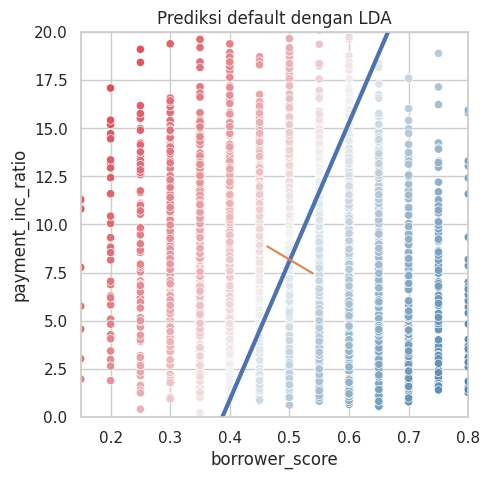

In [11]:
# Gunakan scalings dan titik tengah rata-rata untuk menentukan decision boundary
scalings = loan_lda.scalings_.ravel()
center = np.mean(loan_lda.means_, axis=0)

slope = -scalings[0] / scalings[1]
intercept = center[1] - center[0] * slope

# nilai payment_inc_ratio untuk borrower_score 0 dan 20
x_0 = (0 - intercept) / slope
x_20 = (20 - intercept) / slope

lda_df = pd.concat([loan3000.reset_index(drop=True), pred['default']], axis=1)

fig, ax = plt.subplots(figsize=(5, 5))
sns.scatterplot(x='borrower_score', y='payment_inc_ratio',
                hue='default', data=lda_df,
                palette=sns.diverging_palette(240, 10, n=9, as_cmap=True),
                ax=ax, legend=False)

ax.set_ylim(0, 20)
ax.set_xlim(0.15, 0.8)
ax.plot((x_0, x_20), (0, 20), linewidth=3)
ax.plot(*loan_lda.means_.transpose())
ax.set_title('Prediksi default dengan LDA')
plt.show()

Menggunakan bobot discriminant function, LDA membagi ruang predictor
menjadi dua wilayah yang dipisahkan garis.

### Extensions of Discriminant Analysis

- **Lebih banyak predictor:** LDA tetap bekerja dengan lebih dari dua
  predictor. Satu-satunya batasan adalah jumlah record (estimasi
  covariance matrix memerlukan record yang cukup untuk setiap
  variabel), yang biasanya bukan masalah di data science.
- **Quadratic Discriminant Analysis (QDA):** pada LDA covariance matrix
  diasumsikan sama untuk kedua kelompok (Y = 0 dan Y = 1), sedangkan
  pada QDA covariance matrix boleh berbeda. Dalam praktiknya,
  perbedaan hasilnya pada kebanyakan aplikasi tidak terlalu penting.

### Key Ideas — Discriminant Analysis

- Discriminant analysis bekerja dengan predictor numerik maupun
  kategorikal, dan outcome kategorikal.
- Dengan covariance matrix, dihitung **linear discriminant function**
  yang dipakai untuk membedakan record satu kelas dari kelas lain.
- Fungsi ini diterapkan pada setiap record untuk menghasilkan bobot
  (skor) untuk tiap kelas, yang menentukan perkiraan kelasnya.

# 3. Logistic Regression

**Logistic regression** analog dengan multiple linear regression
(Chapter 4), kecuali outcome-nya **biner**. Berbagai transformasi
dipakai agar masalah dapat diselesaikan dengan model linear. Seperti
discriminant analysis, dan berbeda dengan K-Nearest Neighbor dan naive
Bayes, logistic regression adalah pendekatan **model terstruktur**,
bukan pendekatan yang berpusat pada data. Karena komputasinya cepat dan
modelnya mudah dipakai untuk men-skor data baru, metode ini populer.

### Key Terms

- **Logit** — fungsi yang memetakan probabilitas keanggotaan kelas ke
  rentang −∞ sampai +∞ (bukan 0 sampai 1). Sinonim: *log odds*.
- **Odds** — rasio "sukses" (1) terhadap "tidak sukses" (0).
- **Log odds** — respons pada model yang telah ditransformasi (sekarang
  linear), yang kemudian dipetakan kembali menjadi probabilitas.

### Logistic Response Function dan Logit

Langkah pertama adalah memandang outcome bukan sebagai label biner,
tetapi sebagai probabilitas p bahwa label bernilai 1. Memodelkan p
secara linear langsung:

$$
p = \beta_0 + \beta_1 x_1 + \dots + \beta_q x_q
$$

tidak menjamin p berada di antara 0 dan 1. Karena itu dipakai
**logistic response function** (inverse logit):

$$
p = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x_1 + \dots + \beta_q x_q)}}
$$

Transformasi ini memastikan p tetap berada di antara 0 dan 1.

Untuk menghilangkan eksponen dari penyebut, digunakan **odds**:

$$
\text{Odds}(Y=1) = \frac{p}{1-p}
\qquad
p = \frac{\text{Odds}}{1+\text{Odds}}
$$

Sehingga:

$$
\text{Odds}(Y=1) = e^{\beta_0 + \beta_1 x_1 + \dots + \beta_q x_q}
$$

Dengan mengambil logaritma kedua sisi, diperoleh fungsi linear dari
predictor:

$$
\log(\text{Odds}(Y=1)) = \beta_0 + \beta_1 x_1 + \dots + \beta_q x_q
$$

Fungsi **log-odds (logit)** memetakan p dari [0, 1] ke seluruh nilai
(−∞, +∞). Lingkaran transformasi pun lengkap: model linear dipakai
untuk memprediksi probabilitas, yang kemudian diubah menjadi label
kelas dengan aturan cutoff.

### Grafik Fungsi Logit

Grafik berikut memperlihatkan bagaimana fungsi logit memetakan
probabilitas (0 sampai 1) ke skala yang cocok untuk model linear.

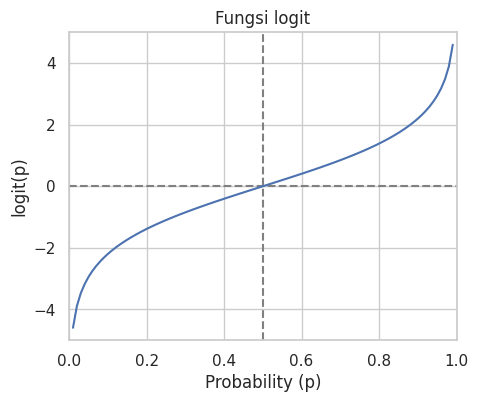

In [12]:
p = np.arange(0.01, 1, 0.01)
df_logit = pd.DataFrame({
    'p': p,
    'logit': np.log(p / (1 - p)),
    'odds': p / (1 - p),
})

fig, ax = plt.subplots(figsize=(5, 4))
ax.axhline(0, color='grey', linestyle='--')
ax.axvline(0.5, color='grey', linestyle='--')
ax.plot(df_logit['p'], df_logit['logit'])
ax.set_ylim(-5, 5)
ax.set_xlim(0, 1)
ax.set_xlabel('Probability (p)')
ax.set_ylabel('logit(p)')
ax.set_title('Fungsi logit')
plt.show()

### Logistic Regression dan GLM

Respons pada rumus logistic regression adalah **log odds** dari outcome
biner 1. Yang kita amati hanyalah outcome biner, bukan log odds-nya,
sehingga diperlukan metode statistik khusus untuk mencocokkan
persamaannya. Logistic regression adalah kasus khusus dari
**generalized linear model (GLM)**.

Di scikit-learn digunakan kelas `LogisticRegression`. Argumen `penalty`
dan `C` dipakai untuk mencegah overfitting melalui regularisasi L1 atau
L2, dan regularisasi aktif secara default. Agar model dicocokkan
**tanpa regularisasi**, `C` diisi dengan nilai yang sangat besar.

In [13]:
predictors = ['payment_inc_ratio', 'purpose_', 'home_', 'emp_len_',
              'borrower_score']
outcome = 'outcome'

X = pd.get_dummies(loan_data[predictors], prefix='', prefix_sep='',
                   drop_first=True, dtype=float)
y = loan_data[outcome]

# C sangat besar = hampir tanpa regularisasi (penalty default adalah L2)
logit_reg = LogisticRegression(C=1e42, solver='liblinear')
logit_reg.fit(X, y)

print('classes_  :', list(logit_reg.classes_))
print('intercept :', logit_reg.intercept_[0])
print()
print('Koefisien:')
pd.DataFrame({'coeff': logit_reg.coef_[0]}, index=X.columns)

classes_  : ['default', 'paid off']
intercept : -1.6380882883923482

Koefisien:


,coeff
payment_inc_ratio,-0.079728
borrower_score,4.611037
debt_consolidation,-0.249342
home_improvement,-0.407614
major_purchase,-0.229376
medical,-0.510087
other,-0.620534
small_business,-1.215662
OWN,-0.048453
RENT,-0.157355


**Catatan tanda koefisien:** scikit-learn menurunkan kelas dari nilai
unik `y` dan mengurutkannya secara alfabet (`default`, `paid off`).
Kelas yang dimodelkan oleh koefisien adalah kelas **kedua**
(`paid off`). Hal ini kebalikan dari R, yang memodelkan peluang
*default*, sehingga **tanda koefisien di Python berlawanan** dengan
yang ada pada output R di buku. Metode `predict` mengembalikan label
kelas, dan `predict_proba` mengembalikan probabilitas dengan urutan
`logit_reg.classes_`.

### Generalized Linear Models (GLM)

GLM memiliki dua komponen utama:

- **Distribusi probabilitas atau family** — *binomial* pada logistic
  regression.
- **Link function** — fungsi transformasi yang memetakan respons ke
  predictor (*logit* pada logistic regression).

Logistic regression adalah GLM yang paling umum. Contoh GLM lain:

- Distribusi **Poisson** untuk data cacah (misalnya berapa kali
  pengguna mengunjungi halaman web dalam periode tertentu).
- **Negative binomial** dan **gamma**, sering dipakai untuk waktu yang
  berlalu (misalnya time to failure).

Penerapan GLM selain logistic regression lebih rumit dan memerlukan
kehati-hatian.

### Predicted Values dari Logistic Regression

Nilai prediksi dari logistic regression berada pada skala **log odds**:

$$
\hat{Y} = \log(\text{Odds}(Y=1))
$$

Probabilitas prediksi diperoleh dari logistic response function:

$$
\hat{p} = \frac{1}{1 + e^{-\hat{Y}}}
$$

In [14]:
# Log probabilitas (prediksi pada skala log)
pred_log = pd.DataFrame(logit_reg.predict_log_proba(X),
                        columns=logit_reg.classes_)
pred_log.describe()

,default,paid off
count,45342.000000,45342.000000
mean,-0.757850,-0.760423
std,0.378032,0.390419
min,-2.768873,-3.538865
25%,-0.985728,-0.977164
50%,-0.697366,-0.688946
75%,-0.472209,-0.467076
max,-0.029476,-0.064787


In [15]:
# Probabilitas langsung dari predict_proba
pred = pd.DataFrame(logit_reg.predict_proba(X),
                    columns=logit_reg.classes_)
pred.describe()

,default,paid off
count,45342.000000,45342.000000
mean,0.500001,0.499999
std,0.167336,0.167336
min,0.062733,0.029046
25%,0.373167,0.376377
50%,0.497895,0.502105
75%,0.623623,0.626833
max,0.970954,0.937267


Nilai-nilai ini berada pada skala 0 sampai 1 dan belum menyatakan
apakah prediksinya *default* atau *paid off*. Kita bisa menyatakan
setiap nilai di atas 0,5 sebagai *default*. Dalam praktiknya, cutoff
yang lebih rendah sering lebih tepat jika tujuannya mengidentifikasi
anggota kelas yang langka (lihat bagian *The Rare Class Problem*).

### Interpreting the Coefficients and Odds Ratios

Keunggulan logistic regression adalah modelnya mudah diinterpretasi
dibanding metode klasifikasi lain. Konsep kuncinya adalah **odds
ratio**. Untuk variabel faktor biner X:

$$
\text{odds ratio} = \frac{\text{Odds}(Y=1 \mid X=1)}{\text{Odds}(Y=1 \mid X=0)}
$$

Jika odds ratio = 2, maka odds bahwa Y = 1 menjadi dua kali lebih
tinggi saat X = 1 dibanding saat X = 0.

Alasan memakai odds ratio: koefisien $\beta_j$ pada logistic
regression adalah **log dari odds ratio** untuk $X_j$. Artinya, odds
ratio adalah $e^{\beta_j}$.

Karena koefisien di scikit-learn memodelkan kelas *paid off*, odds
ratio untuk **default** adalah $e^{-\beta_j}$.

In [16]:
odds_ratio_default = pd.DataFrame({
    'coef_paid_off': logit_reg.coef_[0],
    'odds_ratio_default': np.exp(-logit_reg.coef_[0]),
}, index=X.columns)

odds_ratio_default.round(4)

,coef_paid_off,odds_ratio_default
payment_inc_ratio,-0.0797,1.0830
borrower_score,4.6110,0.0099
debt_consolidation,-0.2493,1.2832
home_improvement,-0.4076,1.5032
major_purchase,-0.2294,1.2578
medical,-0.5101,1.6654
other,-0.6205,1.8599
small_business,-1.2157,3.3725
OWN,-0.0485,1.0496
RENT,-0.1574,1.1704


Pada contoh model di buku, koefisien `purpose_small_business` adalah
sekitar 1,215 (pada skala R, yaitu memodelkan *default*). Nilai ini
berarti pinjaman untuk usaha kecil dibanding pinjaman untuk melunasi
utang kartu kredit meningkatkan odds *default* dibanding *paid off*
sebesar sekitar $e^{1{,}215} \approx 3{,}4$ kali. Pinjaman untuk
membuat atau mengembangkan usaha kecil jelas lebih berisiko.

Odds ratio untuk variabel numerik diinterpretasi serupa: odds ratio
mengukur perubahan odds untuk kenaikan satu unit X. Misalnya
`payment_inc_ratio` naik dari 5 ke 6 meningkatkan odds *default*
sekitar $e^{0{,}08244} \approx 1{,}09$ kali. Skor `borrower_score`
berkisar dari 0 (rendah) sampai 1 (tinggi); odds *default* peminjam
terbaik dibanding terburuk lebih kecil dengan faktor
$e^{-4{,}61264} \approx 0{,}01$, yakni risiko gagal bayar peminjam
terburuk sekitar 100 kali lebih besar daripada peminjam terbaik.

### Linear and Logistic Regression: Similarities and Differences

Keduanya sama-sama mengasumsikan bentuk linear parametrik antara
predictor dan respons. Cara mengeksplorasi dan mencari model terbaik
juga mirip. Perluasan model linear, seperti transformasi spline pada
predictor, juga berlaku pada logistic regression. Perbedaan mendasar:

1. **Cara model dicocokkan** — least squares tidak dapat dipakai.
2. **Sifat dan analisis residual** model.

**Fitting the model.** Linear regression dicocokkan dengan least
squares dan kualitas model dinilai dengan RMSE dan R². Pada logistic
regression tidak ada solusi closed-form, sehingga dipakai **maximum
likelihood estimation (MLE)**, yaitu proses mencari model yang paling
mungkin menghasilkan data yang kita lihat. Algoritmanya adalah
optimasi quasi-Newton yang berulang antara langkah scoring (Fisher's
scoring) dan pembaruan parameter.

Pada proses fitting, model dievaluasi dengan metrik **deviance**:

$$
\text{deviance} = -2 \log P_{\theta}(X_1, X_2, \dots, X_n)
$$

Deviance yang lebih rendah berarti fit yang lebih baik.

> **Handling Factor Variables.** Pada logistic regression, variabel
> faktor dikodekan seperti pada linear regression (reference coding,
> sehingga hanya n − 1 dummy yang dipakai). Di scikit-learn paling
> mudah memakai one-hot encoding dengan `drop_first=True`.

### Assessing the Model

Seperti metode klasifikasi lain, logistic regression dinilai dari
seberapa akurat model mengklasifikasikan data baru. Seperti pada linear
regression, tersedia alat statistik standar untuk memeriksa model,
yaitu standard error koefisien (SE), z-value, dan p-value. Library
`statsmodels` menyediakan implementasi GLM dengan ringkasan lengkap.

In [17]:
y_numbers = [1 if yi == 'default' else 0 for yi in y]

logit_reg_sm = sm.GLM(y_numbers, X.assign(const=1),
                      family=sm.families.Binomial())
logit_result = logit_reg_sm.fit()
logit_result.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:                      y   No. Observations:                45342
Model:                            GLM   Df Residuals:                    45330
Model Family:                Binomial   Df Model:                           11
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -28757.
Date:                Mon, 26 Oct 2026   Deviance:                       57515.
Time:                        08:57:50   Pearson chi2:                 4.54e+04
No. Iterations:                     4   Pseudo R-squ. (CS):             0.1112
Covariance Type:            nonrobust                                         
======================================================================================
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
payment_inc_ratio      0.0797      0.002     32.058      0.000       0.075       0.085
borrower_score        -4.6126      0.084    -55.203      0.000      -4.776      -4.449
debt_consolidation     0.2494      0.028      9.030      0.000       0.195       0.303
home_improvement       0.4077      0.047      8.747      0.000       0.316       0.499
major_purchase         0.2296      0.054      4.277      0.000       0.124       0.335
medical                0.5105      0.087      5.882      0.000       0.340       0.681
other                  0.6207      0.039     15.738      0.000       0.543       0.698
small_business         1.2153      0.063     19.192      0.000       1.091       1.339
OWN                    0.0483      0.038      1.271      0.204      -0.026       0.123
RENT                   0.1573      0.021      7.420      0.000       0.116       0.199
 > 1 Year             -0.3567      0.053     -6.779      0.000      -0.460      -0.254
const                  1.6381      0.074     22.224      0.000       1.494       1.783
======================================================================================
"""

Pada statsmodels respons dikodekan 1 = *default*, sehingga tanda
koefisiennya sama dengan output R di buku (misalnya `borrower_score`
bernilai negatif sekitar −4,6).

Interpretasi p-value memiliki catatan yang sama seperti pada
regression: p-value lebih tepat dipandang sebagai indikator relatif
**variable importance** daripada ukuran formal signifikansi
statistik. Model logistic regression yang respons-nya biner tidak
memiliki RMSE atau R², sehingga dievaluasi dengan metrik klasifikasi
yang lebih umum.

Banyak konsep lain dari linear regression juga berlaku untuk logistic
regression, misalnya stepwise regression, interaction terms, dan
spline terms. Masalah confounding dan correlated variables juga tetap
berlaku. Formula interface dari statsmodels mendukung perluasan ini,
misalnya dengan spline `bs()`.

In [18]:
# Respons numerik 0/1 (1 = default) untuk formula interface statsmodels
loan_data['default_flag'] = (loan_data['outcome'] == 'default').astype(int)

formula = ('default_flag ~ bs(payment_inc_ratio, df=4) + purpose_ + '
           'home_ + emp_len_ + bs(borrower_score, df=4)')

model = smf.glm(formula=formula, data=loan_data, family=sm.families.Binomial())
results = model.fit()

print('Deviance model spline :', round(results.deviance, 2))
print('Deviance model linear :', round(logit_result.deviance, 2))

Deviance model spline : 57487.21
Deviance model linear : 57514.8


### Analysis of Residuals

Salah satu area di mana logistic regression berbeda dari linear
regression adalah analisis residual. Seperti pada linear regression,
**partial residuals** dapat dihitung. Plot partial residual pada
logistic regression biasanya menampilkan **dua awan titik**:

- awan atas — respons 1 (pinjaman *default*)
- awan bawah — respons 0 (pinjaman *paid off*)

Hal ini wajar karena prediksi diukur sebagai logit (log odds), yang
selalu berupa nilai berhingga, sedangkan nilai aktual 0 atau 1
sesuai dengan logit tak hingga. Karena itu residual tidak pernah
bernilai 0 dan titik-titik berada di atas atau di bawah garis fit.
Partial residuals pada logistic regression, meski kurang berharga
dibanding regression biasa, tetap berguna untuk memastikan perilaku
nonlinear dan mengidentifikasi record yang sangat berpengaruh.

Pada buku disebutkan bahwa belum ada implementasi partial residual di
package Python utama. Berikut contoh sederhana untuk
`payment_inc_ratio` dengan **LogisticGAM** dari `pygam`:

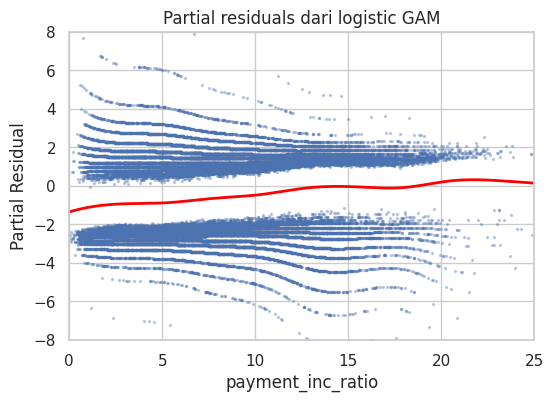

In [19]:
from pygam import LogisticGAM, s, l

gam_X = loan_data[['payment_inc_ratio', 'borrower_score']].values
gam_y = loan_data['default_flag'].values

gam = LogisticGAM(s(0) + s(1)).fit(gam_X, gam_y)

# Kontribusi (log odds) komponen smooth payment_inc_ratio
term_effect = gam.partial_dependence(term=0, X=gam_X)

# Partial residual = working residual + kontribusi komponen
mu = gam.predict_mu(gam_X)
working_resid = (gam_y - mu) / (mu * (1 - mu))
partial_resid = working_resid + term_effect

order = np.argsort(gam_X[:, 0])

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(gam_X[:, 0], partial_resid, s=2, alpha=0.3)
ax.plot(gam_X[order, 0], term_effect[order], color='red', linewidth=2)
ax.set_xlim(0, 25)
ax.set_ylim(-8, 8)
ax.set_xlabel('payment_inc_ratio')
ax.set_ylabel('Partial Residual')
ax.set_title('Partial residuals dari logistic GAM')
plt.show()

Garis merah adalah estimasi kontribusi `payment_inc_ratio`, dan
titik-titik membentuk dua awan: awan atas untuk pinjaman *default* dan
awan bawah untuk pinjaman *paid off*.

> Sebagian output dari `summary` dapat diabaikan. *Dispersion
> parameter* tidak berlaku untuk logistic regression (hanya ada untuk
> jenis GLM lain). Residual deviance dan jumlah iterasi scoring
> berkaitan dengan metode maximum likelihood.

### Key Ideas — Logistic Regression

- Logistic regression seperti linear regression, tetapi outcome-nya
  variabel biner.
- Diperlukan beberapa transformasi agar model dapat dicocokkan sebagai
  model linear, dengan log dari odds ratio sebagai variabel respons.
- Setelah model linear dicocokkan (melalui proses iteratif), log odds
  dipetakan kembali menjadi probabilitas.
- Logistic regression populer karena komputasinya cepat dan modelnya
  dapat men-skor data baru hanya dengan beberapa operasi aritmetika.

# 4. Evaluating Classification Models

Dalam predictive modeling, biasanya beberapa model dilatih, lalu
masing-masing diterapkan pada **holdout sample** untuk menilai
performanya. Kadang, setelah beberapa model dievaluasi dan di-tuning,
jika data cukup banyak, holdout sample ketiga yang belum pernah
dipakai digunakan untuk memperkirakan performa model terpilih pada
data yang benar-benar baru. Istilah *validation* dan *test* dipakai
berbeda-beda antar disiplin untuk holdout sample ini.

### Key Terms

- **Accuracy** — persentase (proporsi) kasus yang diklasifikasikan
  dengan benar.
- **Confusion matrix** — tabel (2×2 pada kasus biner) jumlah record
  berdasarkan status klasifikasi prediksi dan aktual.
- **Sensitivity (recall)** — proporsi seluruh 1 yang diklasifikasikan
  dengan benar sebagai 1.
- **Specificity** — proporsi seluruh 0 yang diklasifikasikan dengan
  benar sebagai 0.
- **Precision** — proporsi 1 hasil prediksi yang benar-benar 1.
- **ROC curve** — plot sensitivity terhadap specificity.
- **Lift** — ukuran seberapa efektif model mengidentifikasi 1 yang
  relatif langka pada berbagai cutoff probabilitas.

Cara paling sederhana mengukur performa klasifikasi adalah menghitung
proporsi prediksi yang benar, yaitu **accuracy**:

$$
\text{accuracy} = \frac{\sum \text{TruePositive} + \sum \text{TrueNegative}}{\text{SampleSize}}
$$

Pada sebagian besar algoritma, setiap kasus diberi estimasi
probabilitas menjadi 1. Titik keputusan (cutoff) bawaan biasanya 0,50.
Alternatifnya adalah probabilitas prevalensi 1 pada data.

## Confusion Matrix

**Confusion matrix** adalah inti metrik klasifikasi: tabel yang
menunjukkan jumlah prediksi benar dan salah menurut jenis responsnya.
Sesuai konvensi, Y = 1 adalah kejadian yang diminati (misalnya
*default*) dan Y = 0 adalah kejadian negatif/biasa (misalnya
*paid off*).

Berikut confusion matrix untuk model `logit_reg` pada data pinjaman:

In [20]:
pred_y = logit_reg.predict(X) == 'default'
true_y = (y == 'default').values

true_pos = true_y & pred_y
true_neg = ~true_y & ~pred_y
false_pos = ~true_y & pred_y
false_neg = true_y & ~pred_y

conf_mat = pd.DataFrame([[np.sum(true_pos), np.sum(false_neg)],
                         [np.sum(false_pos), np.sum(true_neg)]],
                        index=['Y = default', 'Y = paid off'],
                        columns=['Yhat = default', 'Yhat = paid off'])
conf_mat

,Yhat = default,Yhat = paid off
Y = default,14336,8335
Y = paid off,8148,14523


Hasil prediksi berada pada kolom, sedangkan kelas sebenarnya berada
pada baris. Elemen diagonal adalah prediksi yang benar, dan elemen di
luar diagonal adalah prediksi yang salah.

Satu metrik penting yang tidak ditonjolkan secara eksplisit adalah
**false positive rate**. Ketika kelas 1 langka, rasio false positive
terhadap seluruh prediksi positif bisa tinggi, sehingga prediksi 1
justru kemungkinan besar sebenarnya 0. Masalah ini umum pada tes
skrining medis (misalnya mamografi): karena kondisinya relatif
langka, hasil tes positif belum tentu berarti penyakit.

> Pada buku, kelas sebenarnya disajikan pada baris dan prediksi pada
> kolom. Penyajian sebaliknya juga lazim (misalnya pada package `caret`
> di R).

## The Rare Class Problem

Pada banyak kasus, kelas yang diprediksi tidak seimbang: satu kelas
jauh lebih sering muncul. Contohnya klaim asuransi sah versus
penipuan, atau pengunjung biasa versus pembeli di situs web. Kelas
langka (misal klaim penipuan) biasanya yang lebih diminati dan diberi
label 1. Salah mengklasifikasikannya sebagai 0 umumnya lebih mahal
dibanding salah mengklasifikasikan 0 sebagai 1.

Kecuali kelasnya mudah dipisahkan, model yang paling akurat mungkin
hanya model yang mengklasifikasikan semuanya sebagai 0. Contoh: jika
hanya 0,1% pengunjung toko online yang membeli, model yang
memprediksi semua pengunjung pergi tanpa membeli akan 99,9% akurat,
namun tidak berguna. Kita lebih memilih model yang kurang akurat
secara keseluruhan tetapi baik dalam menangkap pembeli.

## Precision, Recall, and Specificity

Metrik yang lebih halus dari accuracy sering dipakai, banyak di
antaranya berasal dari biostatistika untuk menggambarkan performa tes
diagnostik.

$$
\text{precision} = \frac{\sum \text{TruePositive}}{\sum \text{TruePositive} + \sum \text{FalsePositive}}
$$

$$
\text{recall} = \frac{\sum \text{TruePositive}}{\sum \text{TruePositive} + \sum \text{FalseNegative}}
$$

$$
\text{specificity} = \frac{\sum \text{TrueNegative}}{\sum \text{TrueNegative} + \sum \text{FalsePositive}}
$$

- **Precision** mengukur akurasi hasil prediksi positif.
- **Recall (sensitivity)** mengukur kemampuan model memprediksi hasil
  positif, yaitu proporsi 1 yang berhasil diidentifikasi.
- **Specificity** mengukur kemampuan model memprediksi hasil negatif.

In [21]:
conf_mat_sk = confusion_matrix(y, logit_reg.predict(X), labels=['default', 'paid off'])

print('Precision  ', conf_mat_sk[0, 0] / sum(conf_mat_sk[:, 0]))
print('Recall     ', conf_mat_sk[0, 0] / sum(conf_mat_sk[0, :]))
print('Specificity', conf_mat_sk[1, 1] / sum(conf_mat_sk[1, :]))

Precision   0.6376089663760897
Recall      0.6323496978518812
Specificity 0.6405981209474659


scikit-learn memiliki fungsi `precision_recall_fscore_support` yang
menghitung precision dan recall/specificity sekaligus. Recall untuk
kelas *paid off* sama dengan specificity untuk kelas *default*.

In [22]:
precision_recall_fscore_support(y, logit_reg.predict(X),
                                labels=['default', 'paid off'])

(array([0.63760897, 0.63535742]),
 array([0.6323497 , 0.64059812]),
 array([0.63496844, 0.63796701]),
 array([22671, 22671]))

## ROC Curve

Ada *trade-off* antara recall dan specificity. Menangkap lebih banyak
1 biasanya berarti salah mengklasifikasikan lebih banyak 0 sebagai 1.
Classifier ideal akan sangat baik mengklasifikasikan 1 tanpa salah
mengklasifikasikan lebih banyak 0 sebagai 1.

Metrik yang menangkap trade-off ini adalah **ROC curve** (*Receiver
Operating Characteristics*). ROC curve memplot recall (sensitivity)
pada sumbu y terhadap specificity pada sumbu x, ketika cutoff yang
menentukan klasifikasi diubah-ubah. Sumbu x bisa berupa specificity
(1 di kiri, 0 di kanan) atau 1 − specificity (0 di kiri, 1 di kanan);
kurvanya identik.

Proses menghitung ROC curve:

1. Urutkan record berdasarkan probabilitas prediksi menjadi 1, dari
   yang paling mungkin sampai yang paling tidak mungkin.
2. Hitung specificity dan recall kumulatif berdasarkan record yang
   sudah diurutkan.

Di Python digunakan `sklearn.metrics.roc_curve`.

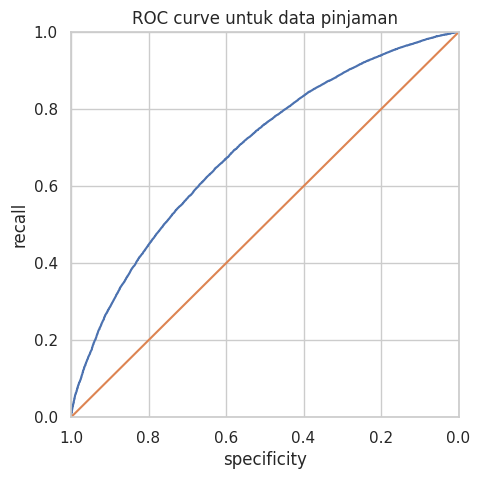

In [23]:
fpr, tpr, thresholds = roc_curve(y, logit_reg.predict_proba(X)[:, 0],
                                 pos_label='default')
roc_df = pd.DataFrame({'recall': tpr, 'specificity': 1 - fpr})

ax = roc_df.plot(x='specificity', y='recall', figsize=(5, 5), legend=False)
ax.set_ylim(0, 1)
ax.set_xlim(1, 0)
ax.plot((1, 0), (0, 1))
ax.set_xlabel('specificity')
ax.set_ylabel('recall')
ax.set_title('ROC curve untuk data pinjaman')
plt.show()

Garis putus-putus diagonal adalah classifier yang tidak lebih baik
dari tebakan acak. Classifier yang sangat efektif (atau tes
diagnostik yang sangat efektif) memiliki ROC yang mendekati pojok kiri
atas: mengidentifikasi banyak 1 tanpa salah mengklasifikasikan banyak
0 sebagai 1.

> **Precision-Recall (PR) Curve.** Selain ROC, PR curve juga
> informatif. PR curve dihitung dengan cara serupa, tetapi data
> diurutkan dari yang paling tidak mungkin ke paling mungkin dan
> precision serta recall kumulatif dihitung. PR curve sangat berguna
> pada data dengan outcome yang sangat tidak seimbang.

## AUC

ROC curve adalah alat grafis yang bermanfaat, tetapi belum menjadi
satu ukuran tunggal performa classifier. Dari ROC curve dapat
dihasilkan metrik **AUC** (*area under the curve*), yaitu total luas
di bawah ROC curve. Semakin besar AUC, semakin efektif classifier-nya.

- AUC = 1 → classifier sempurna: semua 1 terklasifikasi benar dan
  tidak ada 0 yang salah diklasifikasikan sebagai 1.
- AUC = 0,5 → classifier yang tidak efektif (garis diagonal).

In [24]:
# AUC dengan integrasi numerik dan dengan roc_auc_score
print(np.sum(roc_df.recall[:-1] * np.diff(1 - roc_df.specificity)))
print(roc_auc_score([1 if yi == 'default' else 0 for yi in y],
                    logit_reg.predict_proba(X)[:, 0]))

0.691710795288669
0.6917108731135808


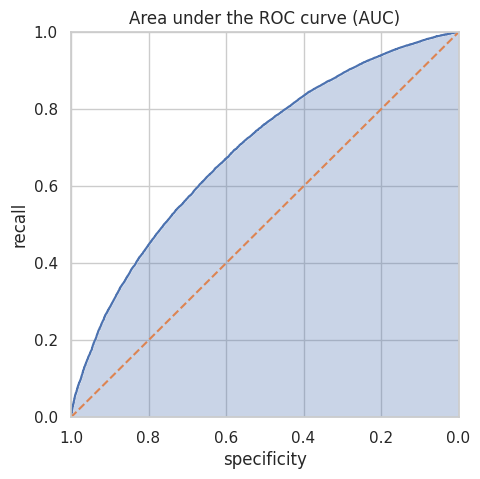

In [25]:
# Visualisasi luas di bawah kurva ROC
fig, ax = plt.subplots(figsize=(5, 5))
ax.fill_between(roc_df.specificity, 0, roc_df.recall, alpha=0.3)
ax.plot(roc_df.specificity, roc_df.recall)
ax.plot((1, 0), (0, 1), linestyle='--')
ax.set_xlim(1, 0)
ax.set_ylim(0, 1)
ax.set_xlabel('specificity')
ax.set_ylabel('recall')
ax.set_title('Area under the ROC curve (AUC)')
plt.show()

Model ini memiliki AUC sekitar 0,69 pada buku, yang menunjukkan
classifier yang relatif lemah.

> **False Positive Rate Confusion.** False positive/negative rate
> sering tertukar dengan specificity atau sensitivity (bahkan pada
> publikasi dan perangkat lunak). Kadang false positive rate
> didefinisikan sebagai proporsi true negative yang dites positif.
> Pada kasus lain (misalnya network intrusion detection) istilah itu
> merujuk pada proporsi sinyal positif yang sebenarnya negatif.

## Lift

AUC lebih baik daripada accuracy sederhana karena menilai bagaimana
classifier menangani trade-off antara accuracy keseluruhan dan
kebutuhan mengidentifikasi 1 yang lebih penting. Namun AUC belum
sepenuhnya menyelesaikan **rare-case problem**, yaitu ketika
probabilitas cutoff perlu diturunkan di bawah 0,5 agar tidak semua
record terklasifikasi sebagai 0.

Konsep **lift** memungkinkan kita menunda pertanyaan "berapa cutoff
optimal?". Record dipertimbangkan berdasarkan urutan probabilitas
prediksi menjadi 1. Dari 10% teratas yang diklasifikasikan sebagai 1,
seberapa lebih baik algoritma dibanding memilih secara acak? Jika kita
mendapat respons 0,3% pada desil teratas dibanding 0,1% secara
keseluruhan, algoritma dikatakan memiliki **lift** (gains) sebesar 3
pada desil teratas.

Untuk membuat **lift chart**, pertama dibuat **cumulative gains
chart** yang menampilkan recall pada sumbu y dan jumlah total record
pada sumbu x. Kurva lift adalah rasio cumulative gains terhadap garis
diagonal yang mewakili pemilihan acak.

Gains chart per desil adalah salah satu teknik tertua dalam predictive
modeling, populer di kalangan direct mail untuk memilih calon
pelanggan dengan peluang respons tertinggi.

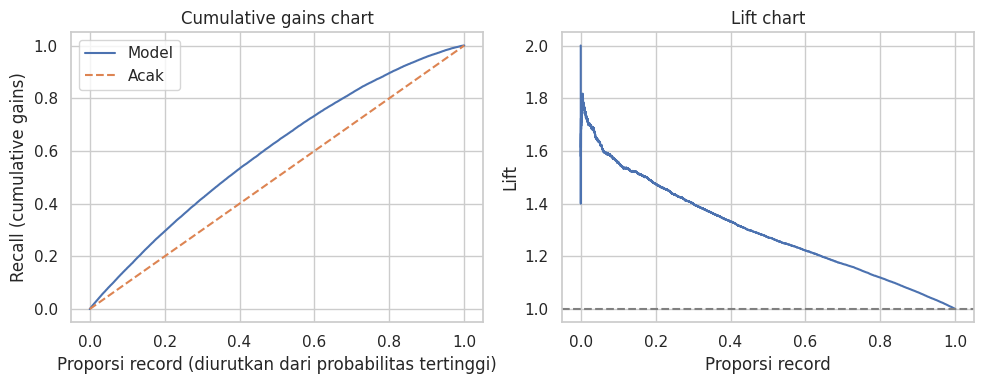

Lift pada 10% teratas: 1.56


In [26]:
# Cumulative gains dan lift per desil
prob_default = logit_reg.predict_proba(X)[:, 0]

gains_df = pd.DataFrame({'prob': prob_default, 'default': true_y.astype(int)})
gains_df = gains_df.sort_values('prob', ascending=False).reset_index(drop=True)
gains_df['cum_default'] = gains_df['default'].cumsum()
gains_df['pct_records'] = (gains_df.index + 1) / len(gains_df)
gains_df['recall'] = gains_df['cum_default'] / gains_df['default'].sum()
gains_df['lift'] = gains_df['recall'] / gains_df['pct_records']

fig, axes = plt.subplots(ncols=2, figsize=(10, 4))

axes[0].plot(gains_df['pct_records'], gains_df['recall'], label='Model')
axes[0].plot([0, 1], [0, 1], linestyle='--', label='Acak')
axes[0].set_xlabel('Proporsi record (diurutkan dari probabilitas tertinggi)')
axes[0].set_ylabel('Recall (cumulative gains)')
axes[0].set_title('Cumulative gains chart')
axes[0].legend()

axes[1].plot(gains_df['pct_records'], gains_df['lift'])
axes[1].axhline(1, linestyle='--', color='grey')
axes[1].set_xlabel('Proporsi record')
axes[1].set_ylabel('Lift')
axes[1].set_title('Lift chart')

plt.tight_layout()
plt.show()

# Lift pada 10% teratas
top10 = gains_df[gains_df['pct_records'] <= 0.10].iloc[-1]
print('Lift pada 10%% teratas: %.2f' % top10['lift'])

> **Uplift.** Kadang istilah uplift dipakai dengan arti yang sama
> dengan lift. Arti lain yang lebih terbatas muncul ketika A/B test
> telah dilakukan dan treatment (A atau B) dipakai sebagai predictor
> pada model prediktif. Uplift adalah peningkatan respons yang
> diprediksi untuk satu kasus dengan treatment A dibanding B,
> ditentukan dengan men-skor kasus tersebut dua kali (predictor
> diatur ke A, lalu ke B). Metode ini dipakai marketer dan konsultan
> kampanye politik untuk menentukan pesan mana yang digunakan pada
> pelanggan atau pemilih mana.

**Lift curve** memungkinkan kita melihat konsekuensi dari pengaturan
cutoff probabilitas yang berbeda, dan dapat menjadi langkah antara
sebelum menentukan cutoff yang tepat. Misalnya, otoritas pajak yang
hanya punya sumber daya terbatas untuk audit akan memakai lift chart
untuk memperkirakan batas antara laporan pajak yang diaudit dan yang
dibiarkan.

### Key Ideas — Evaluating Classification Models

- Accuracy (persentase klasifikasi prediksi yang benar) hanyalah
  langkah pertama dalam mengevaluasi model.
- Metrik lain (recall, specificity, precision) berfokus pada
  karakteristik performa yang lebih spesifik (misalnya recall mengukur
  seberapa baik model mengidentifikasi 1 dengan benar).
- AUC (area under the ROC curve) adalah metrik umum untuk kemampuan
  model membedakan 1 dari 0.
- Lift mengukur seberapa efektif model mengidentifikasi 1, dan sering
  dihitung per desil, mulai dari 1 yang paling mungkin.

# 5. Strategies for Imbalanced Data

Bagian sebelumnya membahas evaluasi model menggunakan metrik di luar
accuracy yang cocok untuk **imbalanced data**, yaitu data di mana
outcome yang diminati (pembelian di situs web, penipuan asuransi, dll.)
langka. Bagian ini membahas strategi tambahan untuk meningkatkan
performa predictive modeling pada data tidak seimbang.

### Key Terms

- **Undersample** (downsample) — menggunakan lebih sedikit record dari
  kelas yang dominan pada model.
- **Oversample** (upsample) — menggunakan lebih banyak record dari kelas
  langka, dengan bootstrapping jika perlu.
- **Up weight / down weight** — memberi bobot lebih (atau kurang) pada
  kelas langka (atau dominan) di dalam model.
- **Data generation** — seperti bootstrapping, tetapi setiap record
  hasil bootstrap sedikit berbeda dari sumbernya.
- **z-score** — nilai hasil standardisasi.
- **K** — jumlah tetangga yang dipertimbangkan pada perhitungan
  nearest neighbor.

## Undersampling

Jika data cukup banyak, seperti pada data pinjaman, salah satu solusi
adalah melakukan **undersample** (downsample) pada kelas yang dominan
sehingga data untuk dimodelkan lebih seimbang antara 0 dan 1. Idenya,
data kelas dominan memiliki banyak record yang redundan. Bekerja dengan
data yang lebih kecil dan seimbang meningkatkan performa model dan
mempermudah persiapan data serta eksplorasi dan pilot model.

Berapa banyak data yang cukup? Bergantung pada aplikasi, tetapi
umumnya puluhan ribu record untuk kelas yang kurang dominan sudah
cukup. Semakin mudah 1 dibedakan dari 0, semakin sedikit data yang
dibutuhkan.

`loan_data` yang dipakai pada logistic regression berasal dari
training set yang **seimbang**: separuh pinjaman lunas dan separuh
*default*. Pada data penuh, hanya sekitar 19% pinjaman yang *default*.

In [27]:
full_train_set = pd.read_csv(DATA_URL + 'full_train_set.csv.gz')
full_train_set['outcome'] = full_train_set['outcome'].astype('category')
for col in ['purpose_', 'home_', 'emp_len_']:
    full_train_set[col] = full_train_set[col].astype('category')

print(full_train_set.shape)
print('percentage of loans in default: ',
      100 * np.mean(full_train_set.outcome == 'default'))

(119987, 19)
percentage of loans in default:  18.894546909248504


Apa yang terjadi jika seluruh data dipakai untuk melatih model?

In [28]:
predictors = ['payment_inc_ratio', 'purpose_', 'home_', 'emp_len_',
              'dti', 'revol_bal', 'revol_util']
outcome = 'outcome'

X = pd.get_dummies(full_train_set[predictors], prefix='', prefix_sep='',
                   drop_first=True, dtype=float)
y = full_train_set[outcome]

full_model = LogisticRegression(C=1e42, solver='liblinear')
full_model.fit(X, y)

print('percentage of loans predicted to default: ',
      100 * np.mean(full_model.predict(X) == 'default'))

percentage of loans predicted to default:  0.9759390600648404


Hanya sebagian kecil pinjaman yang diprediksi *default* (di buku
sekitar 0,39% pada R, atau sekitar 1% pada Python karena perbedaan
implementasi), jauh lebih rendah dari proporsi sebenarnya. Pinjaman
yang lunas "membanjiri" pinjaman yang *default* karena model dilatih
dengan semua data secara setara. Secara intuitif, banyaknya pinjaman
tidak *default* ditambah variabilitas alami pada data predictor
membuat model cenderung menemukan pinjaman tidak *default* yang
kebetulan mirip, bahkan untuk pinjaman yang sebenarnya *default*.
Ketika sampel seimbang dipakai, sekitar 50% pinjaman diprediksi
*default*.

Berikut contoh undersampling manual: mengambil acak sebagian pinjaman
*paid off* agar jumlahnya sama dengan pinjaman *default*.

In [29]:
default_rows = full_train_set[full_train_set['outcome'] == 'default']
paid_rows = full_train_set[full_train_set['outcome'] == 'paid off']

# Undersample kelas dominan (paid off) sehingga jumlahnya sama dengan default
paid_sample = paid_rows.sample(n=len(default_rows), random_state=1)
balanced_set = pd.concat([default_rows, paid_sample])

print(balanced_set['outcome'].value_counts())

X_bal = pd.get_dummies(balanced_set[predictors], prefix='', prefix_sep='',
                       drop_first=True, dtype=float)
y_bal = balanced_set['outcome']

under_model = LogisticRegression(C=1e42, solver='liblinear').fit(X_bal, y_bal)

# Evaluasi pada seluruh training set yang tidak seimbang
print('percentage of loans predicted to default (undersampling): ',
      100 * np.mean(under_model.predict(X) == 'default'))

outcome
default     22671
paid off    22671
Name: count, dtype: int64
percentage of loans predicted to default (undersampling):  42.581279638627514


## Oversampling and Up/Down Weighting

Salah satu kritik terhadap undersampling adalah metode ini membuang
data sehingga tidak memakai seluruh informasi yang ada. Jika data
relatif kecil dan kelas yang lebih langka hanya berisi beberapa ratus
atau ribu record, undersampling berisiko membuang informasi berguna.
Dalam kasus ini, alih-alih downsample kelas dominan, sebaiknya
**oversample** (upsample) kelas yang lebih langka dengan menarik
tambahan baris **dengan pengembalian** (bootstrapping).

Efek serupa bisa dicapai dengan **pembobotan data**. Banyak algoritma
klasifikasi menerima argumen bobot. Di scikit-learn, sebagian besar
metode mengizinkan pemberian bobot pada fungsi `fit` melalui argumen
`sample_weight`.

Bobot untuk pinjaman *default* diatur menjadi 1/p, dengan p adalah
probabilitas *default*. Pinjaman tidak *default* berbobot 1. Jumlah
bobot kedua kelas menjadi kurang lebih sama.

In [30]:
default_wt = 1 / np.mean(full_train_set.outcome == 'default')
wt = [default_wt if outcome == 'default' else 1
      for outcome in full_train_set.outcome]

full_model = LogisticRegression(C=1e42, solver='liblinear')
full_model.fit(X, y, sample_weight=wt)

print('percentage of loans predicted to default (weighting): ',
      100 * np.mean(full_model.predict(X) == 'default'))

percentage of loans predicted to default (weighting):  61.79836148916132


Rata-rata nilai prediksi sekarang sekitar 58% (hasil R pada buku),
bukan 0,39%. Pembobotan adalah alternatif dari upsampling kelas langka
maupun downsampling kelas dominan.

> **Adapting the Loss Function.** Banyak algoritma klasifikasi dan
> regression mengoptimalkan kriteria atau *loss function* tertentu
> (misalnya logistic regression meminimalkan deviance). Beberapa
> literatur mengusulkan modifikasi loss function untuk menghindari
> masalah kelas langka. Dalam praktik hal ini sulit, karena algoritma
> klasifikasi bisa kompleks dan sulit dimodifikasi. Pembobotan adalah
> cara mudah mengubah loss function, yaitu menurunkan kontribusi error
> dari record berbobot rendah dan menaikkan record berbobot tinggi.

## Data Generation

Variasi dari upsampling lewat bootstrapping adalah **data generation**
dengan mengganggu (perturb) record yang ada untuk membuat record baru.
Intuisinya, karena kita hanya mengamati sejumlah instance terbatas,
algoritma tidak memiliki informasi cukup kaya untuk membangun
"aturan" klasifikasi. Dengan membuat record baru yang mirip tetapi
tidak identik, algoritma berkesempatan mempelajari aturan yang lebih
kokoh. Ini sejiwa dengan model ensemble seperti boosting dan bagging
(dibahas pada Chapter 6).

Ide ini populer setelah algoritma **SMOTE** (*Synthetic Minority
Oversampling Technique*) dipublikasikan. SMOTE mencari record yang
mirip dengan record yang di-upsample (lewat nearest neighbor), lalu
membuat record sintetis berupa rata-rata berbobot acak dari record asli
dan tetangganya, dengan bobot dibuat terpisah untuk setiap predictor.
Jumlah record sintetis bergantung pada rasio oversampling yang
dibutuhkan agar data kurang lebih seimbang.

Package Python `imbalanced-learn` mengimplementasikan berbagai metode
over- dan undersampling dengan API yang kompatibel dengan scikit-learn.

In [31]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=1)
X_smote, y_smote = smote.fit_resample(X, y)

print('Sebelum SMOTE:')
print(y.value_counts())
print()
print('Sesudah SMOTE:')
print(pd.Series(y_smote).value_counts())

smote_model = LogisticRegression(C=1e42, solver='liblinear').fit(X_smote, y_smote)
print()
print('percentage of loans predicted to default (SMOTE): ',
      100 * np.mean(smote_model.predict(X) == 'default'))

Sebelum SMOTE:
outcome
paid off    97316
default     22671
Name: count, dtype: int64

Sesudah SMOTE:
outcome
default     97316
paid off    97316
Name: count, dtype: int64

percentage of loans predicted to default (SMOTE):  42.34458733029412


## Cost-Based Classification

Dalam praktik, accuracy dan AUC adalah cara "seadanya" untuk memilih
aturan klasifikasi. Sering kali dapat ditetapkan **perkiraan biaya**
untuk false positive dibanding false negative, dan lebih tepat
memasukkan biaya ini untuk menentukan cutoff terbaik dalam
mengklasifikasikan 1 dan 0.

Misalkan perkiraan biaya *default* pinjaman baru adalah C dan
perkiraan imbal hasil pinjaman yang lunas adalah R. Maka perkiraan
imbal hasil pinjaman:

$$
\text{expected return} = P(Y=0) \times R + P(Y=1) \times C
$$

Daripada sekadar melabeli pinjaman sebagai *default* atau *paid off*,
atau menentukan probabilitas *default*, lebih masuk akal menentukan
apakah pinjaman tersebut memiliki **expected return positif**.
Probabilitas *default* hanyalah langkah antara; harus digabung dengan
nilai total pinjaman untuk menentukan expected profit, yang merupakan
metrik perencanaan akhir bisnis. Misalnya pinjaman bernilai kecil bisa
dilewatkan demi pinjaman lebih besar dengan probabilitas *default*
sedikit lebih tinggi.

Sel berikut hanyalah **ilustrasi** dengan nilai R dan C yang diasumsikan
(bukan dari buku) untuk menunjukkan bagaimana cutoff probabilitas
dapat dipilih berdasarkan biaya.

In [32]:
# ILUSTRASI: nilai R dan C berikut hanya asumsi untuk demonstrasi
R = 0.10    # imbal hasil pinjaman yang lunas (10% dari nilai pinjaman)
C = -1.00   # kerugian pinjaman yang default (100% dari nilai pinjaman)

# Probabilitas default dari model dengan pembobotan (data tidak seimbang)
p_default = full_model.predict_proba(X)[:, list(full_model.classes_).index('default')]

expected_return = (1 - p_default) * R + p_default * C

print('Persentase pinjaman dengan expected return positif: %.1f%%'
      % (100 * np.mean(expected_return > 0)))

# Cutoff probabilitas yang membuat expected return = 0
cutoff = R / (R - C)
print('Cutoff probabilitas default impas: %.3f' % cutoff)

Persentase pinjaman dengan expected return positif: 0.0%
Cutoff probabilitas default impas: 0.091


Dengan asumsi tersebut, pinjaman layak disetujui hanya jika
probabilitas *default* di bawah cutoff impas, yaitu $R/(R-C)$. Cutoff
ini jauh di bawah 0,5, sejalan dengan prinsip bahwa untuk kelas yang
lebih mahal kesalahannya, cutoff sebaiknya tidak default 0,5.

## Exploring the Predictions

Satu metrik tunggal seperti AUC tidak dapat mengevaluasi semua aspek
kecocokan model untuk suatu situasi. Pada buku, Figure 5-8
membandingkan aturan keputusan empat model yang dicocokkan ke data
pinjaman hanya dengan dua predictor, `borrower_score` dan
`payment_inc_ratio`:

1. Linear discriminant analysis (LDA)
2. Logistic regression linear
3. Logistic regression dengan generalized additive model (GAM)
4. Tree model

Wilayah di kiri atas garis adalah prediksi *default*. LDA dan logistic
regression linear memberi hasil hampir identik. Tree model
menghasilkan aturan paling tidak teratur (berundak). GAM adalah
kompromi antara tree model dan model linear.

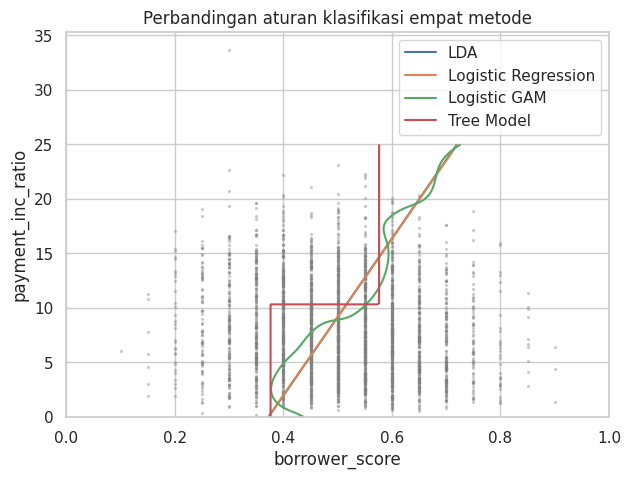

In [33]:
from pygam import LogisticGAM, s

predictors = ['borrower_score', 'payment_inc_ratio']
X2 = loan3000[predictors].values
y2 = (loan3000['outcome'] == 'default').astype(int).values

models = {
    'LDA': LinearDiscriminantAnalysis().fit(X2, y2),
    'Logistic Regression': LogisticRegression(C=1e42, solver='liblinear').fit(X2, y2),
    'Logistic GAM': LogisticGAM(s(0) + s(1)).fit(X2, y2),
    'Tree Model': DecisionTreeClassifier(min_impurity_decrease=0.003,
                                         random_state=1).fit(X2, y2),
}

# Grid untuk menggambar decision boundary (probabilitas default = 0,5)
xx, yy = np.meshgrid(np.linspace(0.0, 1.0, 200), np.linspace(0, 25, 200))
grid = np.c_[xx.ravel(), yy.ravel()]

fig, ax = plt.subplots(figsize=(7, 5))
colors = ['C0', 'C1', 'C2', 'C3']
for (name, model), color in zip(models.items(), colors):
    if name == 'Logistic GAM':
        prob = model.predict_mu(grid)
    else:
        prob = model.predict_proba(grid)[:, 1]
    ax.contour(xx, yy, prob.reshape(xx.shape), levels=[0.5], colors=[color])
    ax.plot([], [], color=color, label=name)

ax.scatter(*X2.T, s=2, color='grey', alpha=0.3)
ax.set_xlabel('borrower_score')
ax.set_ylabel('payment_inc_ratio')
ax.set_title('Perbandingan aturan klasifikasi empat metode')
ax.legend()
plt.show()

Sulit memvisualisasikan aturan prediksi pada dimensi yang lebih
tinggi, atau bahkan membuat wilayah aturan GAM dan tree model. Namun
eksplorasi atas nilai prediksi selalu perlu dilakukan.

### Key Ideas — Strategies for Imbalanced Data

- Data yang sangat tidak seimbang (outcome menarik, yaitu 1, langka)
  bermasalah bagi algoritma klasifikasi.
- Salah satu strategi adalah menyeimbangkan data latih dengan
  undersampling kelas yang melimpah (atau oversampling kelas langka).
- Jika seluruh 1 yang ada masih terlalu sedikit, kita dapat
  melakukan bootstrap pada kasus langka, atau memakai SMOTE untuk
  membuat data sintetis yang mirip kasus langka.
- Data tidak seimbang biasanya menunjukkan bahwa mengklasifikasikan
  satu kelas (1) dengan benar bernilai lebih tinggi, dan rasio nilai
  tersebut harus dimasukkan ke dalam metrik penilaian.

# Key Ideas — Chapter 5

### 1. Classification
Classification adalah proses memprediksi kategori suatu record, dan
merupakan alat dasar predictive analytics. Sering kali kelas yang
diminati adalah kelas langka, yang diberi label 1.

### 2. Propensity Score
Banyak algoritma menghasilkan probabilitas (propensity score) bahwa
suatu record termasuk kelas yang diminati. Probabilitas ini diubah
menjadi keputusan dengan cutoff.

### 3. Naive Bayes
Memakai probabilitas bersyarat dari predictor kategorikal dan asumsi
independensi untuk mengestimasi probabilitas posterior tiap kelas.

### 4. Discriminant Analysis
LDA mencari kombinasi linear predictor yang memaksimalkan pemisahan
antar kelas, menggunakan covariance matrix.

### 5. Logistic Regression
Memodelkan log odds sebagai fungsi linear dari predictor, dicocokkan
dengan maximum likelihood. Koefisien dapat diinterpretasikan sebagai
log odds ratio.

### 6. Evaluasi Model Klasifikasi
Accuracy saja tidak cukup. Gunakan confusion matrix, precision,
recall, specificity, ROC curve, AUC, dan lift.

### 7. Imbalanced Data
Strategi: undersampling, oversampling, up/down weighting, data
generation (SMOTE), dan cost-based classification.

## Kesimpulan

Chapter 5 membahas classification, yaitu proses memprediksi kategori
atau kelas suatu record. Beberapa metode dibahas, yaitu naive Bayes,
discriminant analysis, dan logistic regression. Setiap metode
menghasilkan prediksi kelas sekaligus probabilitas keanggotaan kelas
(propensity) yang dapat diubah menjadi keputusan dengan memilih cutoff.

Mengevaluasi model klasifikasi tidak cukup hanya dengan accuracy,
terutama ketika kelas yang diminati langka. Metrik seperti
confusion matrix, precision, recall, specificity, ROC curve, AUC, dan
lift memberikan gambaran yang lebih lengkap mengenai performa model.

Untuk data yang tidak seimbang, performa model dapat ditingkatkan
dengan undersampling, oversampling, pembobotan data, data generation
(SMOTE), serta dengan memasukkan biaya kesalahan klasifikasi ke dalam
penentuan aturan keputusan. Pada akhirnya, eksplorasi hasil prediksi
tetap diperlukan karena satu metrik saja tidak cukup untuk menilai
kelayakan model.